# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
import os
import glob
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_classification
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
warnings.filterwarnings('ignore')

# Reading of Data

In [3]:
df=pd.read_csv("C:\\Users\\dpree\\Desktop\\Kolate.AI\\463\\Data\\Regression_TL.csv")

In [4]:
df = df.drop(columns=['Unnamed: 0'])

In [5]:
df.shape

(19266, 99)

In [6]:
df.head()

,SUBJID,LBSTRESN,VISITDY_x,LBTEST_Albumin,LBTEST_Alkaline Phosphatase,LBTEST_Carcinoembryonic Antigen,LBTEST_Creatinine,LBTEST_Hemoglobin,LBTEST_Lactate Dehydrogenase,LBTEST_Platelets,LBTEST_White Blood Cells,LBBASE_N,LBBASE_Y,LSSITE,LSCAT,min_VISITDY,min_LSSLD,max_VISITDY,max_LSSLD,LSSLD_Diff,Percentage_LSSLD_Change,VISITDY_y,LSNEWANY,WEIGHT,VISITDY,RSTRESP_Progressive disease,RSTRESP_Stable disease,RSTRESP_Unknown,RSNTRESP_Progressive disease,RSNTRESP_Stable disease,RSNTRESP_Unknown,TRT,ATRT,SXANY,DTHDYX,DTHX,PFSDYCR,PFSCR,DIAGMONS,AGE,SEX,B_WEIGHT,RACE,B_ECOG,HISSUBTY,DIAGTYPE,AESEVCD,AEPT_ACNE,AEPT_CELLULITIS,AEPT_CONTUSION,AEPT_DERMATITIS,AEPT_DERMATITIS ACNEIFORM,AEPT_DERMATITIS ALLERGIC,AEPT_DRY SKIN,AEPT_ECCHYMOSIS,AEPT_ECZEMA,AEPT_ERYTHEMA,AEPT_ESCHAR,AEPT_EXCESSIVE GRANULATION TISSUE,AEPT_EXCORIATION,AEPT_EXFOLIATIVE RASH,AEPT_FOLLICULITIS,AEPT_FUNGAL RASH,AEPT_FUNGAL SKIN INFECTION,AEPT_HERPES SIMPLEX,AEPT_HERPES ZOSTER,AEPT_HYPERHIDROSIS,AEPT_IMPETIGO,AEPT_INTERTRIGO,AEPT_JAUNDICE,AEPT_NIGHT SWEATS,AEPT_ONYCHOCLASIS,AEPT_PAIN OF SKIN,AEPT_PALLOR,AEPT_PALMAR-PLANTAR ERYTHRODYSAESTHESIA SYNDROME,AEPT_PENILE ULCERATION,AEPT_PERIANAL ABSCESS,AEPT_PERIORBITAL OEDEMA,AEPT_PETECHIAE,AEPT_PRURITUS,AEPT_RASH,AEPT_RASH ERYTHEMATOUS,AEPT_RASH PAPULAR,AEPT_RASH PRURITIC,AEPT_RASH PUSTULAR,AEPT_ROSACEA,AEPT_SCAB,AEPT_SKIN DISORDER,AEPT_SKIN EXFOLIATION,AEPT_SKIN FISSURES,AEPT_SKIN INDURATION,AEPT_SKIN IRRITATION,AEPT_SKIN LESION,AEPT_SKIN MACERATION,AEPT_SKIN TOXICITY,AEPT_SKIN ULCER,AEPT_TELANGIECTASIA,AECONT_N,AECONT_Y
0,1,199.395854,23.604167,2,2,2,2,2,2,2,2,8,8,Gastrointestinal,Target lesion,-12.0,240.0,163.0,269.0,29.0,10.780669,85.0,N,45.769231,102.5,1,11,3,9,3,3,panit. plus best supportive care,panit. plus best supportive care,Y,218.0,1.0,84.0,1.0,54.983607,68.0,Male,48.0,White or Caucasian,Symptoms but ambulatory,No sub-type,Colon,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0
1,1,199.395854,23.604167,2,2,2,2,2,2,2,2,8,8,Gastrointestinal,Target lesion,-12.0,240.0,163.0,269.0,29.0,10.780669,85.0,Y,45.769231,102.5,1,11,3,9,3,3,panit. plus best supportive care,panit. plus best supportive care,Y,218.0,1.0,84.0,1.0,54.983607,68.0,Male,48.0,White or Caucasian,Symptoms but ambulatory,No sub-type,Colon,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0
2,1,199.395854,23.604167,2,2,2,2,2,2,2,2,8,8,Gastrointestinal,Target lesion,-12.0,240.0,163.0,269.0,29.0,10.780669,85.0,N,45.769231,102.5,1,11,3,9,3,3,panit. plus best supportive care,panit. plus best supportive care,Y,218.0,1.0,84.0,1.0,54.983607,68.0,Male,48.0,White or Caucasian,Symptoms but ambulatory,No sub-type,Colon,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0
3,1,199.395854,23.604167,2,2,2,2,2,2,2,2,8,8,Gastrointestinal,Target lesion,-12.0,240.0,163.0,269.0,29.0,10.780669,85.0,Y,45.769231,102.5,1,11,3,9,3,3,panit. plus best supportive care,panit. plus best supportive care,Y,218.0,1.0,84.0,1.0,54.983607,68.0,Male,48.0,White or Caucasian,Symptoms but ambulatory,No sub-type,Colon,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,0.0
4,1,199.395854,23.604167,2,2,2,2,2,2,2,2,8,8,Gastrointestinal,Target lesion,-12.0,240.0,163.0,269.0,29.0,10.780669,85.0,N,45.769231,102.5,1,11,3,9,3,3,panit. plus best supportive care,panit. plus best supportive care,Y,218.0,1.0,84.0,1.0,54.983607,68.0,Male,48.0,White or Caucasian,Symptoms but ambulatory,No s

In [7]:
df.shape

(19266, 99)

In [8]:
df['LSSLD_Change'] = np.where(df['Percentage_LSSLD_Change'] > 30, 1, 0)

# Feature Selection using Random Forest 

In [10]:
df1=df

In [11]:
df1 = pd.get_dummies(df1, drop_first=True)
X = df1.drop('LSSLD_Change', axis=1)
y = df1['LSSLD_Change']

In [12]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

RandomForestClassifier(random_state=42)

In [13]:
importances = rf.feature_importances_
# Create a dataframe for feature importances
feature_importances_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feature_importances_df = feature_importances_df.sort_values(by='Importance', ascending=False)

In [14]:
feature_importances_df.head(40)

,Feature,Importance
18,Percentage_LSSLD_Change,0.444504
17,LSSLD_Diff,0.155024
14,min_LSSLD,0.055515
16,max_LSSLD,0.035132
30,PFSDYCR,0.019892
21,VISITDY,0.019299
32,DIAGMONS,0.017604
15,max_VISITDY,0.017225
22,RSTRESP_Progressive disease,0.016870
33,AGE,0.014828


# Forming New Datasets

In [16]:
df=df[['SUBJID','LSSLD_Change','LSSITE','RSTRESP_Stable disease','PFSDYCR','DTHDYX','DIAGMONS','LBSTRESN','B_WEIGHT','AECONT_N','RSTRESP_Stable disease','AESEVCD','AEPT_DERMATITIS ACNEIFORM','AEPT_ERYTHEMA','AEPT_PRURITUS','AECONT_Y','AEPT_EXFOLIATIVE RASH','LBBASE_N','TRT','ATRT','WEIGHT']]
df.shape

(19266, 21)

In [17]:
df.head()

,SUBJID,LSSLD_Change,LSSITE,RSTRESP_Stable disease,PFSDYCR,DTHDYX,DIAGMONS,LBSTRESN,B_WEIGHT,AECONT_N,RSTRESP_Stable disease,AESEVCD,AEPT_DERMATITIS ACNEIFORM,AEPT_ERYTHEMA,AEPT_PRURITUS,AECONT_Y,AEPT_EXFOLIATIVE RASH,LBBASE_N,TRT,ATRT,WEIGHT
0,1,0,Gastrointestinal,11,84.0,218.0,54.983607,199.395854,48.0,3.0,11,3.0,0.0,0.0,0.0,0.0,0.0,8,panit. plus best supportive care,panit. plus best supportive care,45.769231
1,1,0,Gastrointestinal,11,84.0,218.0,54.983607,199.395854,48.0,3.0,11,3.0,0.0,0.0,0.0,0.0,0.0,8,panit. plus best supportive care,panit. plus best supportive care,45.769231
2,1,0,Gastrointestinal,11,84.0,218.0,54.983607,199.395854,48.0,3.0,11,3.0,0.0,0.0,0.0,0.0,0.0,8,panit. plus best supportive care,panit. plus best supportive care,45.769231
3,1,0,Gastrointestinal,11,84.0,218.0,54.983607,199.395854,48.0,3.0,11,3.0,0.0,0.0,0.0,0.0,0.0,8,panit. plus best supportive care,panit. plus best supportive care,45.769231
4,1,0,Gastrointestinal,11,84.0,218.0,54.983607,199.395854,48.0,3.0,11,3.0,0.0,0.0,0.0,0.0,0.0,8,panit. plus best supportive care,panit. plus best supportive care,45.769231


In [18]:
dfnew=df.drop_duplicates(keep='first')
dfnew.shape

(504, 21)

In [19]:
df_encoded=dfnew

In [20]:
df_encoded = df_encoded.dropna()

# Regression Models

In [22]:
X = df_encoded.drop('LSSLD_Change', axis=1)
y = df_encoded['LSSLD_Change']

categorical_cols = X.select_dtypes(include=['object']).columns
X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [23]:
param_grids = {
    'Logistic Regression': {
        'C': [0.001, 0.01, 0.1, 1, 10, 100],
        'penalty': ['l1', 'l2'],
        'solver': ['liblinear']  # 'liblinear' for both l1 and l2 penalties
    },
    'Random Forest': {
        'n_estimators': [50, 100, 200],
        'max_depth': [None, 10, 20],
        'min_samples_split': [2, 5],
        'min_samples_leaf': [1, 2]
    },
    'SVM': {
        'C': [0.1, 1, 10],
        'kernel': ['rbf', 'linear'],
        'gamma': ['scale', 'auto']
    },
    'XGBoost': {
        'n_estimators': [50, 100, 200],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.1, 0.3],
        'subsample': [0.8, 0.99],
        'colsample_bytree': [0.8, 0.99]
    }
}

In [33]:
models = {
    'Logistic Regression': LogisticRegression(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(random_state=42),
    'XGBoost': XGBClassifier(random_state=42)
}

Tuning Logistic Regression...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters for Logistic Regression: {'C': 0.001, 'penalty': 'l1', 'solver': 'liblinear'}
Best cross-validation score: 0.5722
Test Accuracy: 0.7143
Classification Report:
              precision    recall  f1-score   support

           0       0.71      1.00      0.83        35
           1       0.00      0.00      0.00        14

    accuracy                           0.71        49
   macro avg       0.36      0.50      0.42        49
weighted avg       0.51      0.71      0.60        49

Feature importance for Logistic Regression:


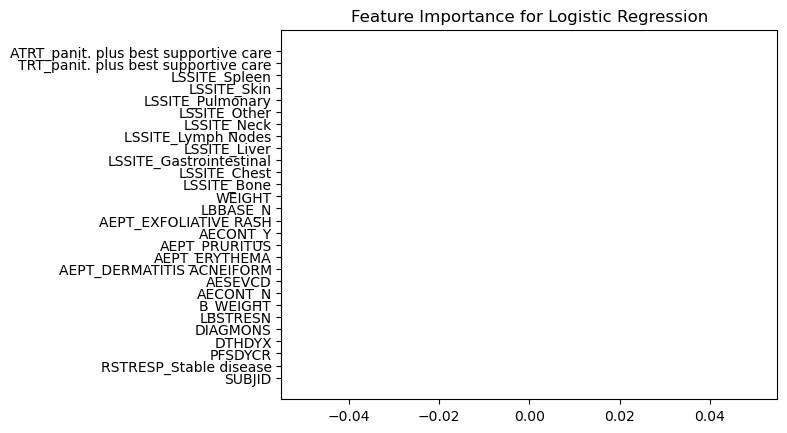



Tuning Random Forest...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters for Random Forest: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best cross-validation score: 0.6804
Test Accuracy: 0.6939
Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.71      0.77        35
           1       0.47      0.64      0.55        14

    accuracy                           0.69        49
   macro avg       0.65      0.68      0.66        49
weighted avg       0.73      0.69      0.71        49

Feature importance for Random Forest:


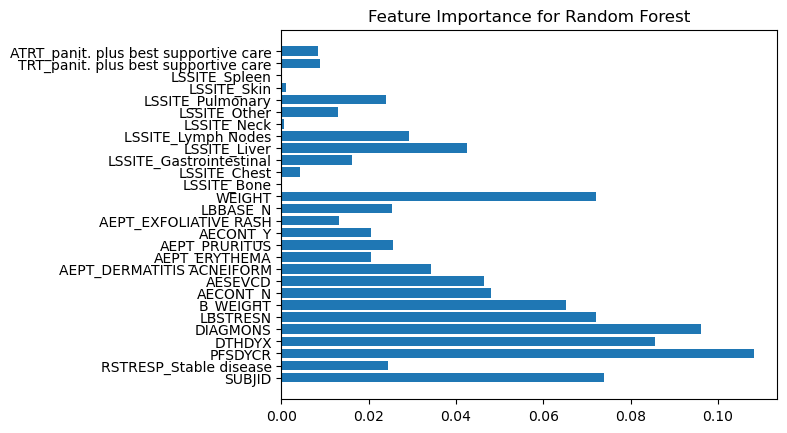



Tuning SVM...
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best parameters for SVM: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best cross-validation score: 0.6497
Test Accuracy: 0.7551
Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.80      0.82        35
           1       0.56      0.64      0.60        14

    accuracy                           0.76        49
   macro avg       0.71      0.72      0.71        49
weighted avg       0.77      0.76      0.76        49

Feature importance for SVM:
Feature importance not available for non-linear SVM models.


Tuning XGBoost...
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters for XGBoost: {'colsample_bytree': 0.8, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 50, 'subsample': 0.99}
Best cross-validation score: 0.7059
Test Accuracy: 0.7347
Classification Report:
              precision    recall  f1-score   support

     

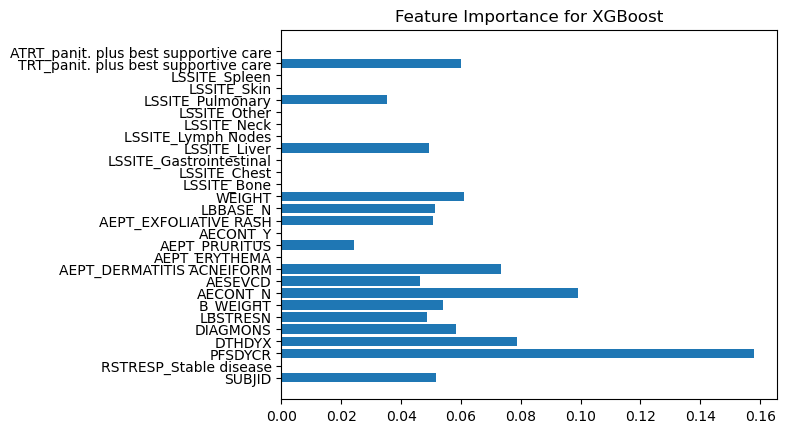

In [45]:
for name, model in models.items():
    print(f"Tuning {name}...")
    grid_search = GridSearchCV(estimator=model, param_grid=param_grids[name], 
                               cv=5, n_jobs=-1, verbose=1, scoring='accuracy')
    grid_search.fit(X_train_scaled, y_train)
    
    print(f"Best parameters for {name}: {grid_search.best_params_}")
    print(f"Best cross-validation score: {grid_search.best_score_:.4f}")
    
    # Use the best model to make predictions
    best_model = grid_search.best_estimator_
    y_pred = best_model.predict(X_test_scaled)
    
    # Evaluate the model
    print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
    # Feature Importance
    print(f"Feature importance for {name}:")
    
    if name == 'Logistic Regression':
        # For Logistic Regression, feature importance is the absolute value of the coefficients
        importance = np.abs(best_model.coef_).flatten()
        feature_names = X_train.columns
        plt.barh(feature_names, importance)
        plt.title(f"Feature Importance for {name}")
        plt.show()
        
    elif name == 'Random Forest':
        # For Random Forest, use feature_importances_
        importance = best_model.feature_importances_
        feature_names = X_train.columns
        plt.barh(feature_names, importance)
        plt.title(f"Feature Importance for {name}")
        plt.show()
        
    elif name == 'XGBoost':
        # For XGBoost, use feature_importances_
        importance = best_model.feature_importances_
        feature_names = X_train.columns
        plt.barh(feature_names, importance)
        plt.title(f"Feature Importance for {name}")
        plt.show()
        
    else:
        # For SVM, feature importance is not straightforward for non-linear kernels
        if best_model.kernel == 'linear':
            importance = np.abs(best_model.coef_).flatten()
            feature_names = X_train.columns
            plt.barh(feature_names, importance)
            plt.title(f"Feature Importance for {name}")
            plt.show()
        else:
            print(f"Feature importance not available for non-linear {name} models.")

    print("\n")

In [46]:
conf_matrix = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(conf_matrix)

Confusion Matrix:
[[30  5]
 [ 8  6]]


In [49]:
feature_importance_ae = pd.DataFrame({'feature': X.columns, 'importance': best_model.feature_importances_})
feature_importance_ae = feature_importance_ae.sort_values('importance', ascending=False)

print("Top features for pe_tl:")
print(feature_importance_ae.head(20))

ValueError: All arrays must be of the same length